# 3. PCA and dimensionality reduction
PCA is fitted **inside** each CV fold (Pipeline), never on test data.

components for 95% variance: 23


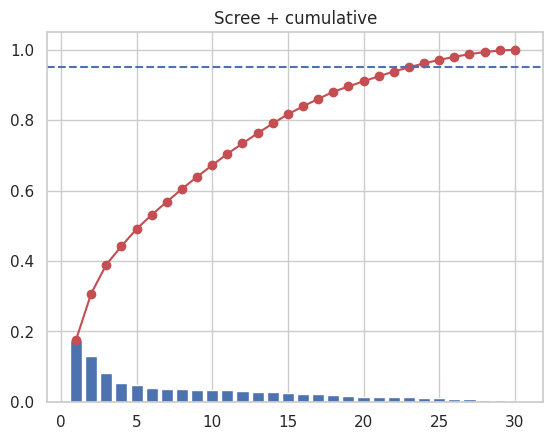

In [1]:
from pathlib import Path
import json, pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
ROOT = Path.cwd() if (Path.cwd()/'data').exists() else Path.cwd().parent
RES = ROOT/'results'; sns.set_theme(style='whitegrid')
v = pd.read_csv(RES/'pca_variance.csv')
n95 = int((v.cumulative<0.95).sum()+1); print('components for 95% variance:', n95)
plt.bar(v.component, v.explained_variance_ratio); plt.plot(v.component, v.cumulative, 'o-r'); plt.axhline(.95, ls='--'); plt.title('Scree + cumulative'); plt.show()

In [2]:
s = pd.read_csv(RES/'summary.csv')
p = s.pivot(index='model', columns='condition', values='cv_accuracy_mean')
((p['PCA 95%']-p['Original 30'])*100).round(2).sort_values().rename('PCA effect (points)')

model
Decision Tree          -3.01
AdaBoost               -2.52
Gradient Boosting      -1.86
Random Forest          -1.86
XGBoost                -1.65
Stacking               -0.66
KNN                    -0.02
SVM RBF                 0.00
Logistic Regression     0.02
Soft Voting             0.53
Gaussian NB            25.41
Name: PCA effect (points), dtype: float64

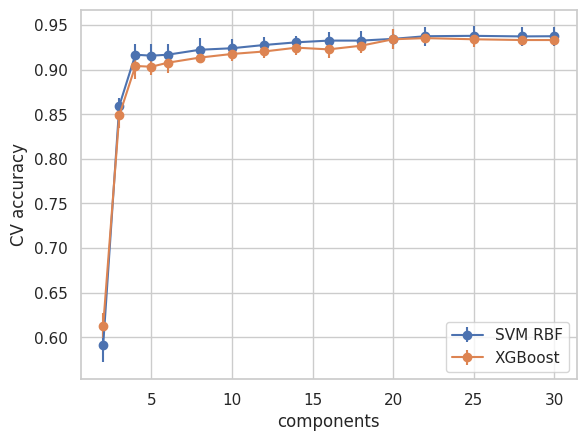

In [3]:
sw = pd.read_csv(RES/'pca_component_sweep.csv')
for n,g in sw.groupby('model'): plt.errorbar(g.n_components, g.cv_accuracy_mean, g.cv_accuracy_std, marker='o', label=n)
plt.legend(); plt.xlabel('components'); plt.ylabel('CV accuracy'); plt.show()

**Observation:** 23 of 30 components keep 95% of the variance, so PCA removes only a quarter of the dimensions. It helps Gaussian NB enormously (decorrelation), leaves SVM/Logistic Regression/KNN almost unchanged, and **hurts tree models** (Decision Tree, Random Forest, AdaBoost, Gradient Boosting) because PCA mixes the original binary-like features that trees split on cleanly. PCA maximises variance, not class separation.